In [1]:
# Imports
import glob
import json
import numpy as np
import astropy.units as u
from astropy.io import fits
from scipy.optimize import minimize
import lmfit
import winnie
from winnie import RCRDI, RCDatabase
from winnie.roman import generate_rc_psf_grid
from winnie.plot import quick_implot, mpl_centered_extent, mpl, plt
from winnie.modeling import obj_fn, make_region_of_interest_mask
from winnie.utils import dist_to_pt

plt.style.use('winnie.winnie_mplstyle') # Comment this out or replace it if you prefer a different plot style

winnie.utils.setup_jupyter_display()

### Roman Coronagraph (RC): disks with a known model

Forward modeling (FM) of circumstellar disks in RC data, where the disk model is known and only its brightness is fit. Three parts:
1. Bertrand's exozodi ring (face-on).
2. Bertrand's inclined exozodi disk.
3. The same inclined disk plus a planet buried in it.

Data are simulated: default corgisim (HLC band 1, `hlc_ni_3e-8` dark hole) through default corgidrp L3, two SCI rolls (±13°) and two REF visits, plus the satellite-spot frames of each visit. Ask Jorge Llop-Sayson for `roman_rc_example.tar.gz` and unpack it in this folder. Each dataset folder holds the L3 frames, the disk model used for the injection, and the truth.

What differs from JWST (tutorials 1–7):
- Units are e⁻/s (L3), not MJy/sr.
- Default L3 has no star position; `RCDatabase` finds it from each visit's satellite-spot frames (corgidrp `find_star`). `RCRDI.load_concat` registers every frame on it and combines the frames of each visit into one image.
- No distortion correction (no SIAF for RC yet).
- The PSF grid comes from corgisim. PSFs are unit-total; the mask attenuation is a separate transmission map built from the grid throughput. The cached grid file is in `psfgrid/`, so corgisim is not needed here.

In [2]:
base_dir = './roman_rc_example/'
grid_file = glob.glob(f'{base_dir}psfgrid/rc_psfgrid_*.fits')[0]
grid_norm = fits.getval(grid_file, 'NORM') # unocculted total of the grid PSFs (incident -> detected e-/s)
lamd = fits.getval(grid_file, 'RES_MAS')*u.mas # lambda/D in band 1
err_scale = 0.92 # per-roll ERR calibration for these sims: robust std of RDI/ERR on a disk-free set (stage5_hlc1_planet)

def load_rc(sub):
    """RCRDI for one dataset folder: SCI/REF split from the PSFREF header keyword."""
    files = np.array(sorted(glob.glob(f'{base_dir}{sub}/l3/*_l3_.fits')))
    psfref = np.array([fits.getval(f, 'PSFREF', 0) for f in files], dtype=bool)
    Database = RCDatabase(f'{base_dir}{sub}/')
    Database.add_concat(files[~psfref], files[psfref]) # sat-spot frames are only used to locate the star
    wdb = RCRDI(Database, output_subdir='WinnieRDI', pad_data='auto', overwrite=True, verbose=False)
    wdb.load_concat(0)
    return wdb

def load_disk_model(sub):
    """Known raw disk model (north up) in incident e-/s per detector-pixel area, its pixel scale and star pixel."""
    hdu = fits.open(f'{base_dir}{sub}/disk_model.fits')[0]
    return hdu.data, hdu.header['PXSCALE']*u.arcsec/u.pixel, np.array([hdu.header['STARX'], hdu.header['STARY']])

# Part 1: Bertrand ring

In [3]:
wdb = load_rc('ring')
rdi_reduc = wdb.run_rdi(save_products=True)

print('Rolls (deg):', wdb._posangs_sci)
print('Star (px):', wdb.c_star)
print('Pixel scale:', wdb.pxscale)

Rolls (deg): [347.0015702  13.0015702]
Star (px): [36.87894997 36.83020958]
Pixel scale: 0.02179994075159873 arcsec / pix


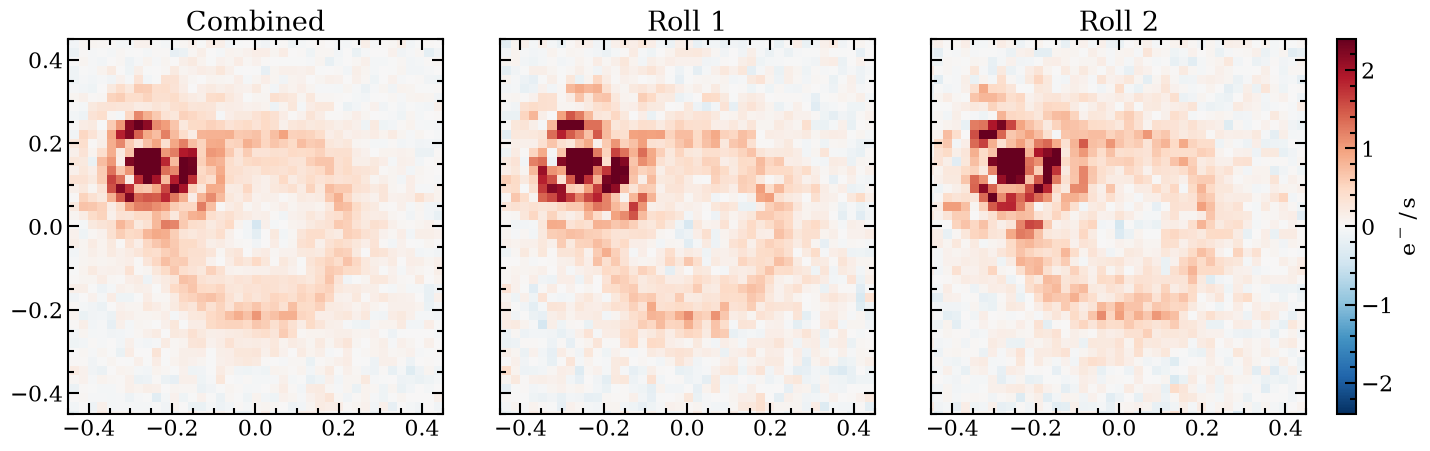

In [4]:
fig,axes,cbar = quick_implot([rdi_reduc.im, *rdi_reduc.rolls], show=False, clim_perc=99.5, cmap='RdBu_r', extent=rdi_reduc.extent, show_ticks=True, lims=[-0.45,0.45],
                              cbar=True, cbar_kwargs=dict(pad=0.02), panelsize=(5.5,4.5), cbar_label=r'e$^-\,/\,$s')

for i,label in enumerate(['Combined', 'Roll 1', 'Roll 2']):
    axes[i].set_title(label)

plt.show()

The ring at 3.9–5.0 λ/D plus the companion at 6 λ/D (PA 60°). Classical RDI scales the references against the whole frame, ring included, so part of the ring gets subtracted. FM accounts for this.

Next, the PSF grid. `grid_file` loads the cached corgisim grid; with corgisim installed, `grid_kwargs=dict(optics=CorgiOptics(...))` builds one (~1 h, cached after that).

In [5]:
wdb.prepare_convolution(osamp=2, fov_pixels=41, grid_fn=generate_rc_psf_grid, grid_kwargs=dict(grid_file=grid_file))

The raw model is Bertrand's `xzmodels3`, the same image the simulation started from, sampled at 1/4 of the detector pixel. Times `grid_norm`, it is in the L3 units.

Note: keep the model pixel scale such that it becomes an integer factor of the oversampled grid pixel (here exactly 2). Otherwise `convolve_model` slightly stretches the model when resampling.

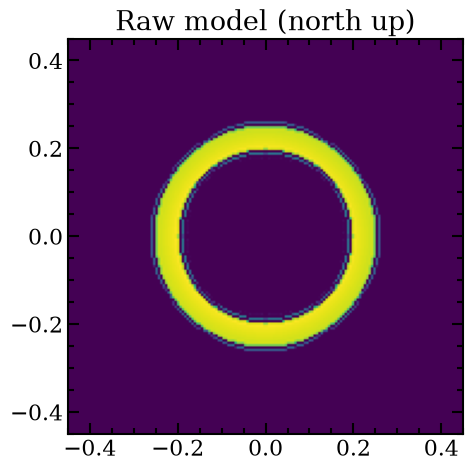

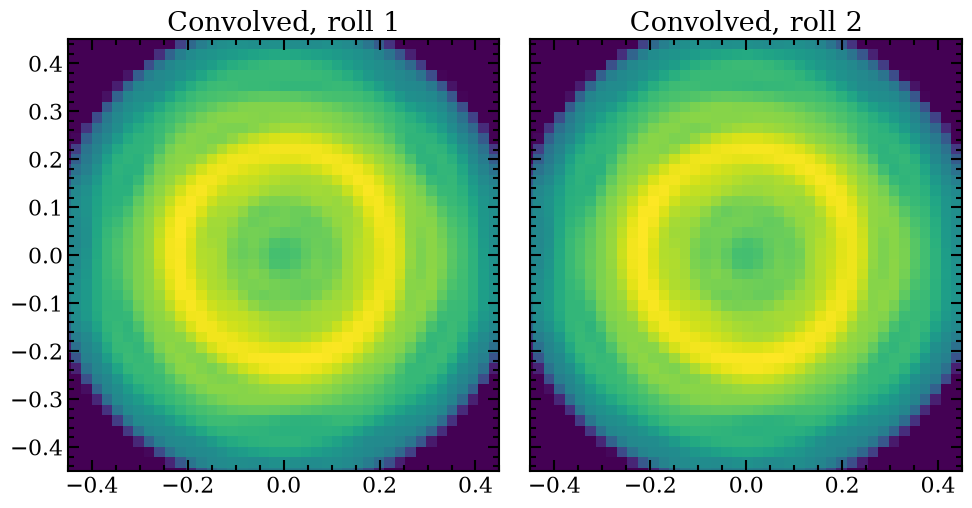

In [6]:
raw_model, raw_model_pxscale, raw_model_center = load_disk_model('ring')
raw_model = raw_model*grid_norm

model_cube = wdb.convolver.convolve_model(raw_model, raw_model_pxscale, raw_model_center)

raw_extent = mpl_centered_extent(raw_model.shape, raw_model_center, raw_model_pxscale)
fig,ax = quick_implot(raw_model, norm=mpl.colors.LogNorm, norm_kwargs=dict(clip=True), clim='0.001*99.99%, 99.99%', show=False,
                      extent=raw_extent, lims=[-0.45,0.45], show_ticks=True)
ax.set_title('Raw model (north up)')

fig,axes = quick_implot(model_cube, norm=mpl.colors.LogNorm, norm_kwargs=dict(clip=True), clim='0.001*99.99%, 99.99%', show=False,
                        extent=rdi_reduc.extent, lims=[-0.45,0.45], show_ticks=True)
for i,ax in enumerate(axes):
    ax.set_title(f'Convolved, roll {i+1}')

plt.show()

The brightness is the only free parameter. As in tutorial 6 with the background, the convolved model goes into `obj_fn` as a fixed component with autoscaling on: `obj_fn` forward models it once and finds the best scale by linear least squares. No lmfit parameters are needed.

As in tutorial 2: the fit uses non-derotated rolls, and the region of interest (ROI) masks the companion. The ROI is 3–9 λ/D, the dark hole.

Ring scale: 0.801, chi2_r = 0.88


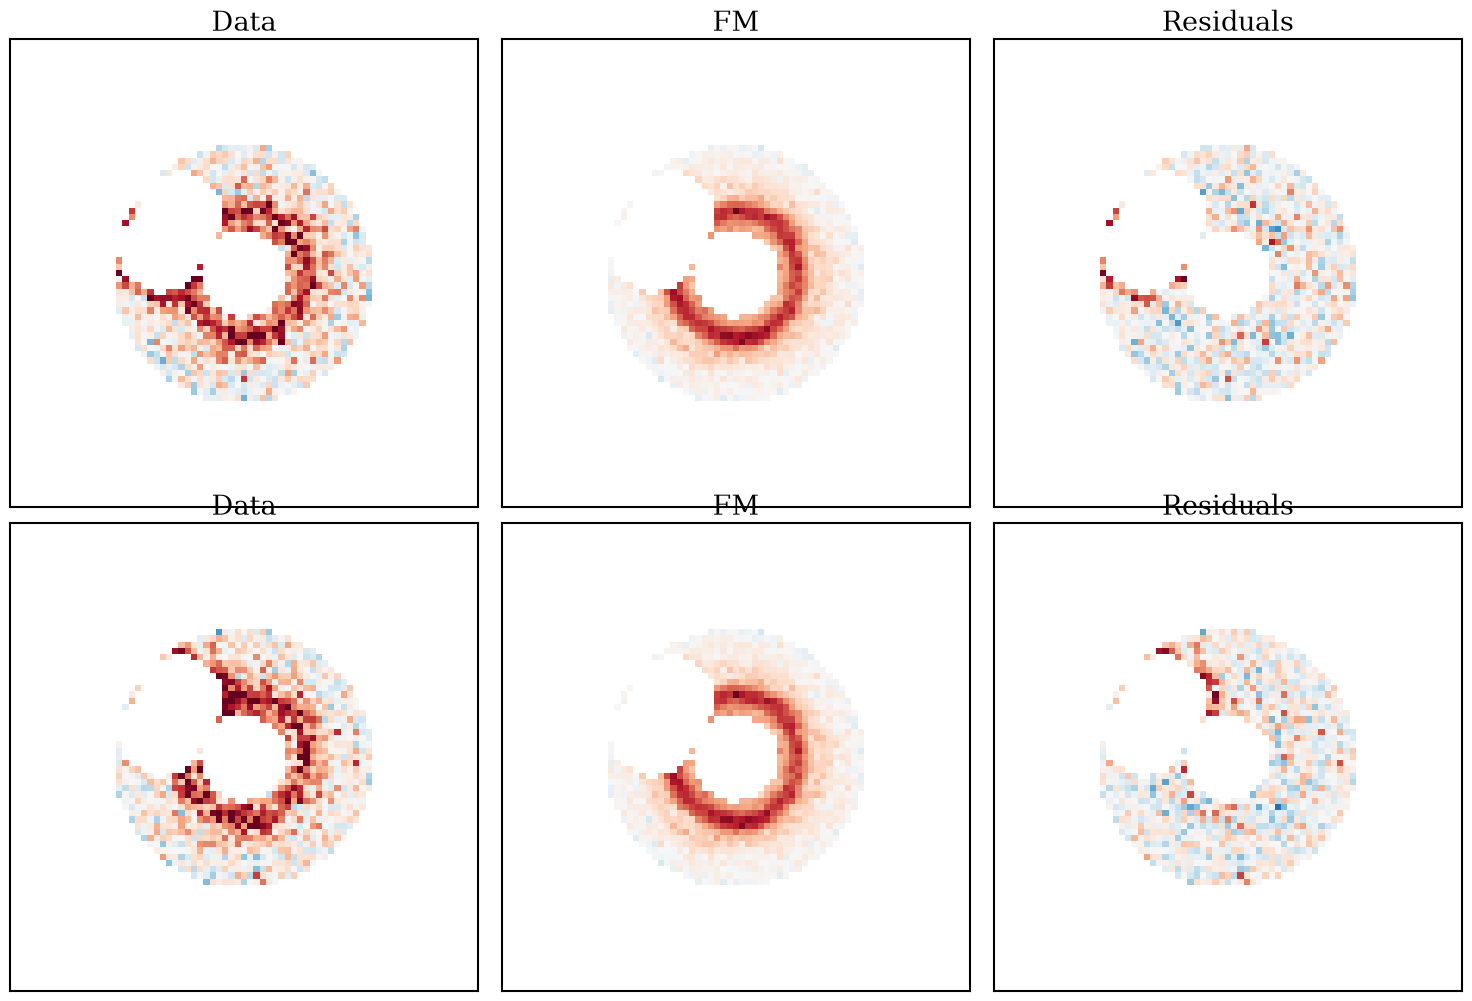

In [7]:
roi_rmin, roi_rmax = 3*lamd.to(u.arcsec).value, 9*lamd.to(u.arcsec).value

info = json.load(open(f'{base_dir}ring/info.json'))
dxy_northup = np.array([[-c['dra_mas'], c['ddec_mas']] for c in info['companions']])/1e3 # arcsec, +x west
rexcl_northup = 3*lamd.to(u.arcsec).value

wdb.rdi_presets()
rdi_reduc_nd = wdb.run_rdi(derotate=False)
roi = make_region_of_interest_mask(rdi_reduc_nd, wdb, rmin=roi_rmin, rmax=roi_rmax, dxy_northup=dxy_northup, rexcl_northup=rexcl_northup, units=u.arcsec)

def fit_known_models(rdi_reduc_nd, wdb, roi, model_cubes, labels):
    """Best scale of each convolved model (obj_fn autoscale), its FM reductions, and the reduced chi2 in the ROI."""
    fmreducs = []
    for cube in model_cubes:
        wdb.set_circumstellar_model(model_cube=cube)
        fmreducs.append(wdb.run_rdi(forward_model=True, derotate=False))
    kws = dict(modelcubes_in=model_cubes, modellabels_in=labels, fmreducs_in=fmreducs, autoscale_in=[True]*len(labels),
               err_weighting=err_scale*rdi_reduc_nd.err_rolls, count=False, clear_each_call=False)
    res = obj_fn(lmfit.Parameters(), rdi_reduc_nd, wdb, roi, None, **kws)
    out = obj_fn(lmfit.Parameters(), rdi_reduc_nd, wdb, roi, None, return_soln=True, **kws)
    return out[0], out[4], np.sum(res**2)/(res.size - len(labels))

coeffs, fmrdi_reduc_nd, chi2r = fit_known_models(rdi_reduc_nd, wdb, roi, [model_cube], ['ring'])
print(f'Ring scale: {coeffs[0]:.3f}, chi2_r = {chi2r:.2f}')

pim = np.array([rdi_reduc_nd.rolls, fmrdi_reduc_nd.rolls, rdi_reduc_nd.rolls-fmrdi_reduc_nd.rolls]).transpose((1,0,2,3))
fig,axes = quick_implot(np.where(roi, pim, np.nan), clim_perc=99., cmap='RdBu_r', interpolation='None', show=False)
for ax,label in zip(axes, ['Data', 'FM', 'Residuals']*2):
    ax.set_title(label)
plt.show()

The residuals are at the noise level away from the companion (masked; it is not in the model). The scale is checked against the truth below.

Now, as in tutorial 2: set the scaled model, then the derotated FM and MCRDI.

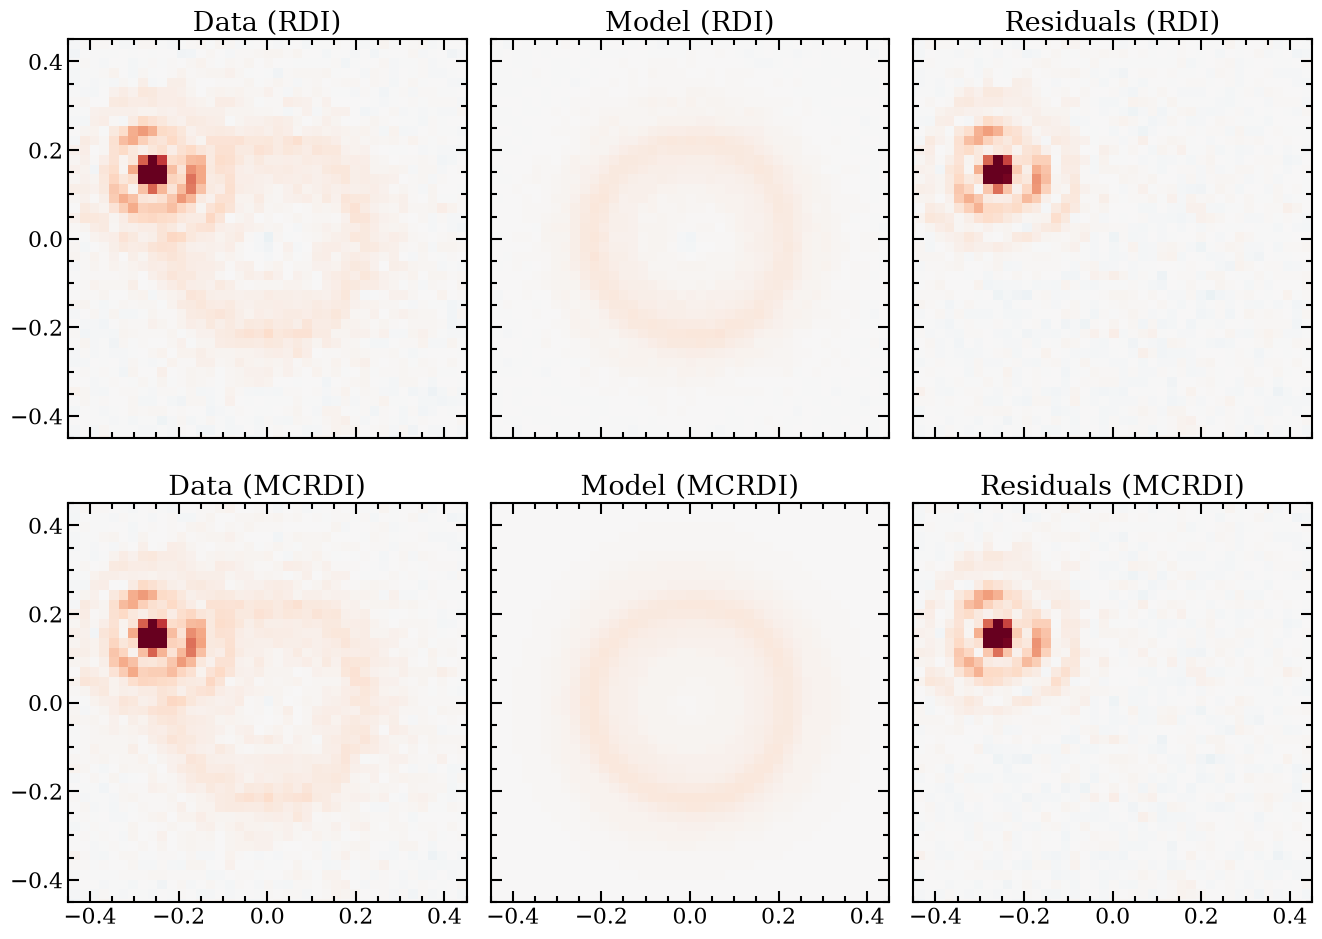

In [8]:
wdb.set_circumstellar_model(model_cube=coeffs[0]*model_cube)
fmrdi_reduc = wdb.run_rdi(forward_model=True)

wdb.mcrdi_presets()
mcrdi_reduc = wdb.run_rdi(save_products=True)
model_reduc = wdb.make_model_reduc(match_reduc=mcrdi_reduc, save_products=True)

fig,axes = quick_implot([[rdi_reduc.im, fmrdi_reduc.im, rdi_reduc.im-fmrdi_reduc.im],
                         [mcrdi_reduc.im, model_reduc.im, mcrdi_reduc.im-model_reduc.im]],
                         cmap='RdBu_r', clim_perc=99.9, show=False,
                         panelsize=(4.5,5.0), extent=rdi_reduc.extent,
                         lims=[-0.45,0.45], show_ticks=True)

labels = ['Data (RDI)', 'Model (RDI)', 'Residuals (RDI)',
          'Data (MCRDI)', 'Model (MCRDI)', 'Residuals (MCRDI)']

for i,ax in enumerate(axes):
    ax.set_title(labels[i])

MCRDI recovers the ring without the over-subtraction, and the disk-subtracted MCRDI leaves the companion and noise.

Check against the truth: the noiseless disk injected in each roll (`truth_disk_*.fits`, same detector frame as L3, star at the center).

In [9]:
def truth_ratio(sub, wdb, model_cube, roi_rmin=roi_rmin, roi_rmax=roi_rmax):
    """Scale of the convolved model that best matches the noiseless injected disk, per roll."""
    out = []
    for cube, posang in zip(model_cube, wdb._posangs_sci):
        f = [f for f in glob.glob(f'{base_dir}{sub}/truth_disk_*.fits') if abs((fits.getval(f, 'PA_APER') - posang + 180) % 360 - 180) < 0.1][0]
        truth = fits.getdata(f)
        c0 = (np.array(truth.shape[::-1]) - 1)/2
        model = winnie.utils.pad_or_crop_image(cube, truth.shape, cent=wdb.c_star, new_cent=c0, cval0=0.)
        r = dist_to_pt(c0, *truth.shape[::-1])*wdb.pxscale.value
        m = (r > roi_rmin) & (r < roi_rmax)
        out.append(np.sum(model[m]*truth[m])/np.sum(model[m]**2))
    return np.array(out)

ratio = truth_ratio('ring', wdb, model_cube)
print('Injected / model, per roll:', ratio.round(3))
print(f'Fitted scale: {coeffs[0]:.3f}, i.e. {coeffs[0]/ratio.mean():.3f} of the injected ring')

Injected / model, per roll: [0.847 0.847]
Fitted scale: 0.801, i.e. 0.946 of the injected ring


- **The template is 0.85 of what was injected.** corgisim's `simulate_2d_scene` applies its flux conversion slightly differently from how the template was made (0.854× in band 1). This is a simulation convention, not Winnie.
- **The fit recovers 0.95 of the injected ring:**
  - L3 itself carries the ring at about 0.96 of the noiseless injection;
  - the ring's hard edges make the scale very sensitive to radial scale (about 8% per 1% stretch);
  - corgisim places sources at 22.06 mas/px, while the header says 21.8.

# Part 2: inclined disk

Bertrand's `xzmodels4`: an exozodi cloud at about 60° inclination, centrally peaked, with its forward-scattering side brighter. This time the injected disk was convolved with cgisim (corosims), not corgisim. So the data PSF and the FM PSF come from different codes (about 2% rms PSF shape difference); expect a scale a few % lower than for the ring.

The same procedure, more compactly. No companion to mask.

Disk scale: 0.820, chi2_r = 0.90
Injected / model, per roll: [0.925 0.925]
Recovered: 0.887 of the injected disk


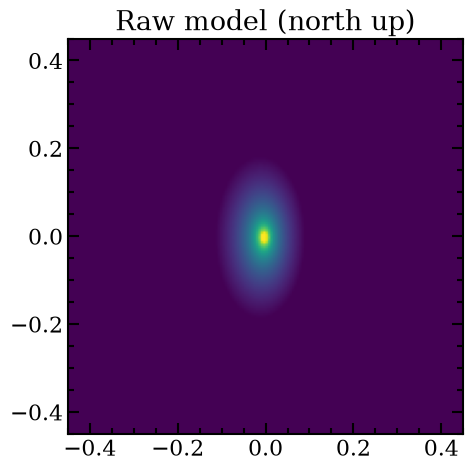

In [10]:
wdb = load_rc('incl_disk')
rdi_reduc = wdb.run_rdi(save_products=True)
wdb.prepare_convolution(osamp=2, fov_pixels=41, grid_fn=generate_rc_psf_grid, grid_kwargs=dict(grid_file=grid_file))

raw_model, raw_model_pxscale, raw_model_center = load_disk_model('incl_disk')
raw_model = raw_model*grid_norm
model_cube = wdb.convolver.convolve_model(raw_model, raw_model_pxscale, raw_model_center)

rdi_reduc_nd = wdb.run_rdi(derotate=False)
roi = make_region_of_interest_mask(rdi_reduc_nd, wdb, rmin=roi_rmin, rmax=roi_rmax, units=u.arcsec)

coeffs, fmrdi_reduc_nd, chi2r = fit_known_models(rdi_reduc_nd, wdb, roi, [model_cube], ['disk'])
ratio = truth_ratio('incl_disk', wdb, model_cube)
print(f'Disk scale: {coeffs[0]:.3f}, chi2_r = {chi2r:.2f}')
print('Injected / model, per roll:', ratio.round(3))
print(f'Recovered: {coeffs[0]/ratio.mean():.3f} of the injected disk')

raw_extent = mpl_centered_extent(raw_model.shape, raw_model_center, raw_model_pxscale)
fig,ax = quick_implot(raw_model, norm=mpl.colors.LogNorm, norm_kwargs=dict(clip=True), clim='0.001*99.99%, 99.99%', show=False,
                      extent=raw_extent, lims=[-0.45,0.45], show_ticks=True)
ax.set_title('Raw model (north up)')
plt.show()

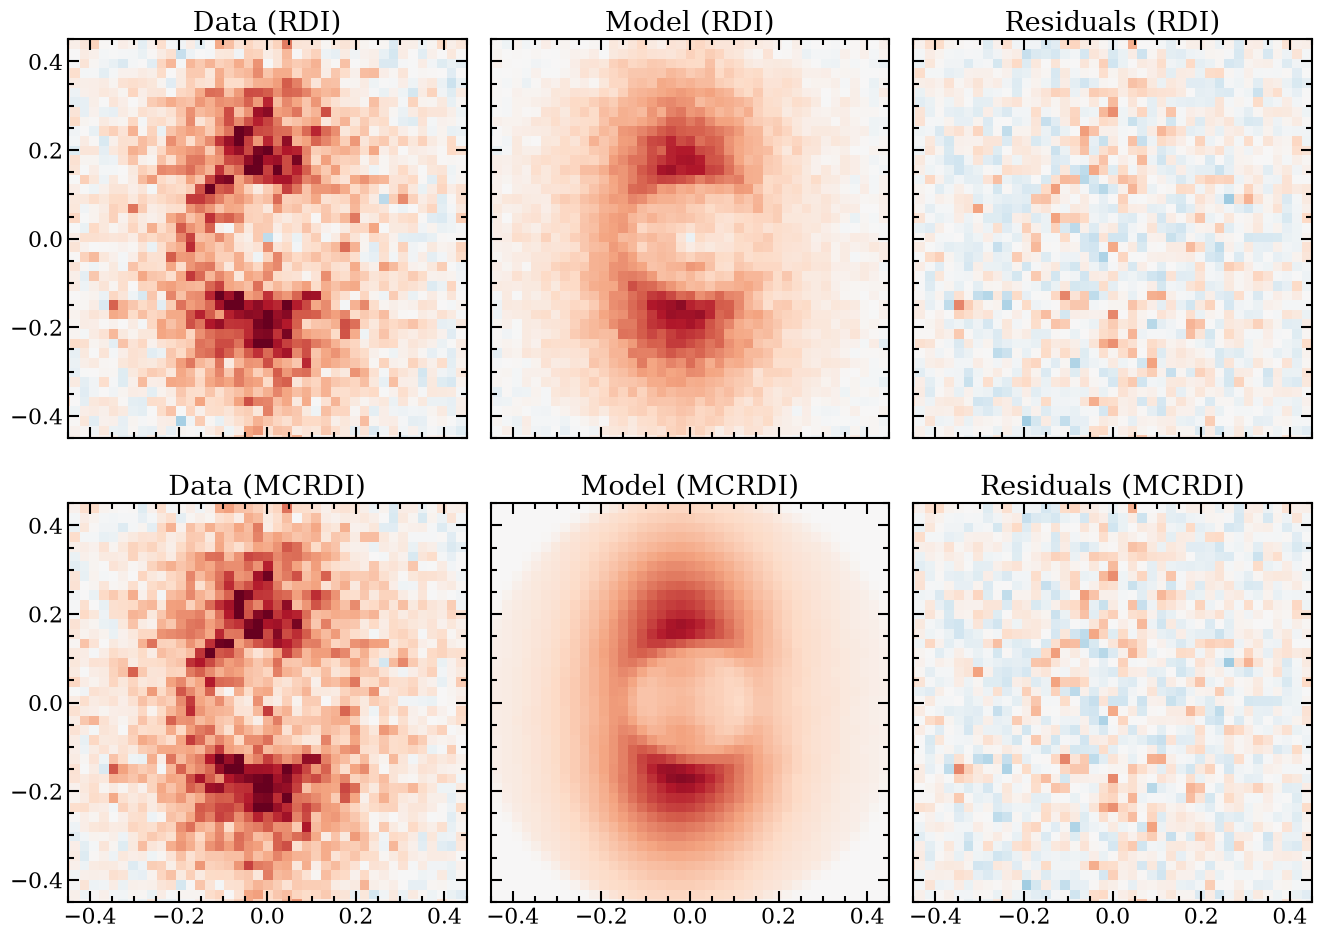

In [11]:
wdb.set_circumstellar_model(model_cube=coeffs[0]*model_cube)
fmrdi_reduc = wdb.run_rdi(forward_model=True)

wdb.mcrdi_presets()
mcrdi_reduc = wdb.run_rdi(save_products=True)
model_reduc = wdb.make_model_reduc(match_reduc=mcrdi_reduc, save_products=True)

fig,axes = quick_implot([[rdi_reduc.im, fmrdi_reduc.im, rdi_reduc.im-fmrdi_reduc.im],
                         [mcrdi_reduc.im, model_reduc.im, mcrdi_reduc.im-model_reduc.im]],
                         cmap='RdBu_r', clim_perc=99.9, show=False,
                         panelsize=(4.5,5.0), extent=rdi_reduc.extent,
                         lims=[-0.45,0.45], show_ticks=True)

labels = ['Data (RDI)', 'Model (RDI)', 'Residuals (RDI)',
          'Data (MCRDI)', 'Model (MCRDI)', 'Residuals (MCRDI)']
for i,ax in enumerate(axes):
    ax.set_title(labels[i])

About 0.89 of the injected disk: the extra loss compared with the ring is the cgisim vs corgisim PSF shape (2% rms), which a corgisim grid can't absorb. With real data, the grid would come from measured off-axis PSFs instead.

The disk keeps rising inside 3 λ/D, where the grid is least accurate (the transmission map changes fastest there), so this region is left out of the ROI. The residual next to the mask edge is that mismatch, not noise.

# Part 3: inclined disk + planet

Same disk and setup, plus a planet at 4.5 λ/D, PA 30°, about 30° off the disk major axis. The planet's peak is about twice the disk surface brightness there.

In [12]:
sub = 'incl_disk_planet'
wdb = load_rc(sub)
rdi_reduc = wdb.run_rdi(save_products=True)
wdb.prepare_convolution(osamp=2, fov_pixels=41, grid_fn=generate_rc_psf_grid, grid_kwargs=dict(grid_file=grid_file))

raw_model, raw_model_pxscale, raw_model_center = load_disk_model(sub)
raw_model = raw_model*grid_norm
model_cube = wdb.convolver.convolve_model(raw_model, raw_model_pxscale, raw_model_center)

rdi_reduc_nd = wdb.run_rdi(derotate=False)
roi = make_region_of_interest_mask(rdi_reduc_nd, wdb, rmin=roi_rmin, rmax=roi_rmax, units=u.arcsec)
coeffs, fmrdi_reduc_nd, chi2r = fit_known_models(rdi_reduc_nd, wdb, roi, [model_cube], ['disk'])
print(f'Disk scale: {coeffs[0]:.3f}, chi2_r = {chi2r:.2f}')

wdb.set_circumstellar_model(model_cube=coeffs[0]*model_cube)
fmrdi_reduc = wdb.run_rdi(forward_model=True)
wdb.mcrdi_presets()
mcrdi_reduc = wdb.run_rdi(save_products=True)
model_reduc = wdb.make_model_reduc(match_reduc=mcrdi_reduc)
csssub_reduc = mcrdi_reduc - model_reduc

Disk scale: 0.886, chi2_r = 0.95


In the RDI image the planet blends with the bright side of the disk. In the disk-subtracted MCRDI image it stands out. S/N map: the disk-subtracted image over its robust std in 2 px annuli.

Peak S/N 8.7 at dx, dy = [-0.108  0.198] arcsec


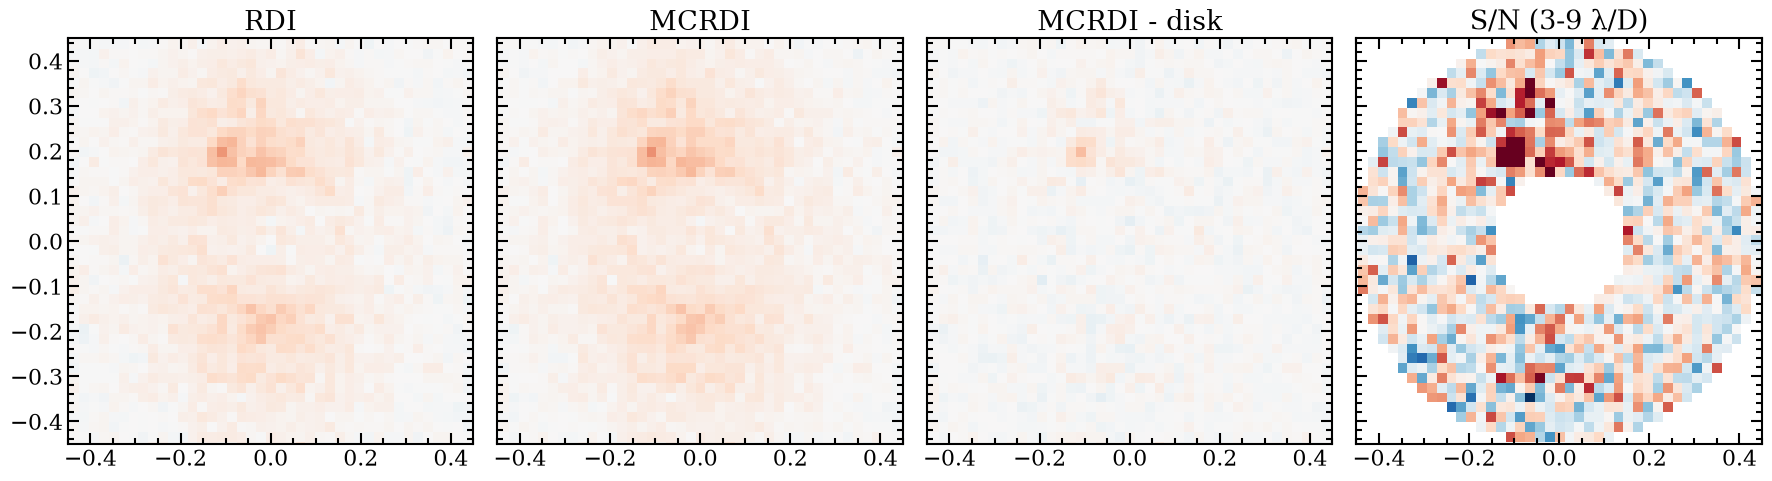

In [13]:
def snr_map(reduc, wdb, width=2.):
    """Image over the robust std in annuli of `width` px (the planet barely biases it at these sizes)."""
    r = dist_to_pt(reduc.c_star, reduc.nx, reduc.ny)
    snr = np.full(reduc.im.shape, np.nan)
    for r0 in np.arange(0, r.max(), width):
        s = (r >= r0) & (r < r0 + width) & np.isfinite(reduc.im)
        if s.sum() > 10:
            snr[s] = reduc.im[s]/(1.4826*np.nanmedian(np.abs(reduc.im[s] - np.nanmedian(reduc.im[s]))))
    return snr

snr = snr_map(csssub_reduc, wdb)
r = dist_to_pt(wdb.c_star, wdb.nx, wdb.ny)*wdb.pxscale.value
snr_dh = np.where((r > roi_rmin) & (r < roi_rmax), snr, np.nan)
iy, ix = np.unravel_index(np.nanargmax(snr_dh), snr_dh.shape)
dxy_peak = (np.array([ix, iy]) - wdb.c_star)*wdb.pxscale.value # arcsec, north-up detector axes (+x west)
print(f'Peak S/N {snr_dh[iy, ix]:.1f} at dx, dy = {dxy_peak.round(3)} arcsec')

fig,axes = quick_implot([rdi_reduc.im, mcrdi_reduc.im, csssub_reduc.im, snr_dh], cmap='RdBu_r', clim_perc=99.9, show=False,
                        panelsize=(4.5,5.0), extent=rdi_reduc.extent, lims=[-0.45,0.45], show_ticks=True)
for ax,label in zip(axes, ['RDI', 'MCRDI', 'MCRDI - disk', 'S/N (3-9 $\\lambda/D$)']):
    ax.set_title(label)
plt.show()

Now fit the disk and planet together. The planet model is a narrow Gaussian (σ = 0.3 px) on the sky, convolved with the grid like the disk; this picks up the right off-axis PSF and mask transmission at each roll. (A single-pixel delta doesn't work: Winnie's rotation treats exact zeros as missing data.)

Both scales come from the autoscaling, as before. The position is refined with Nelder–Mead on the same objective, starting at the S/N peak.

In [14]:
def point_model(dxy, n=81, sigma=0.3):
    """North-up unit-flux Gaussian at dxy (arcsec, +x west) from the star, at the detector pixel scale."""
    c0 = (n - 1)/2
    y, x = np.indices((n, n))
    xy = c0 + np.asarray(dxy)/wdb.pxscale.value
    m = np.exp(-((x - xy[0])**2 + (y - xy[1])**2)/(2*sigma**2))
    return m/m.sum(), np.array([c0, c0])

def planet_cube(dxy):
    m, c = point_model(dxy)
    return wdb.convolver.convolve_model(m, wdb.pxscale, c)

wdb.rdi_presets()
roi = make_region_of_interest_mask(rdi_reduc_nd, wdb, rmin=roi_rmin, rmax=roi_rmax, units=u.arcsec)

def chi2r_joint(dxy):
    return fit_known_models(rdi_reduc_nd, wdb, roi, [model_cube, planet_cube(dxy)], ['disk', 'planet'])[2]

res = minimize(chi2r_joint, dxy_peak, method='Nelder-Mead', options=dict(xatol=1e-4, fatol=1e-4))
dxy_fit = res.x
coeffs, fmrdi_reduc_nd, chi2r = fit_known_models(rdi_reduc_nd, wdb, roi, [model_cube, planet_cube(dxy_fit)], ['disk', 'planet'])

truth = json.load(open(f'{base_dir}{sub}/info.json'))['companions'][0]
dxy_true = np.array([-truth['dra_mas'], truth['ddec_mas']])/1e3
print(f'Disk scale: {coeffs[0]:.3f}, chi2_r = {chi2r:.2f}')
print(f"Planet flux: {coeffs[1]:.2f} e-/s (truth {truth['flux_e_s']:.2f}, ratio {coeffs[1]/truth['flux_e_s']:.3f})")
print(f'Planet position: {dxy_fit.round(4)} arcsec (truth {dxy_true.round(4)}); offset {np.hypot(*(dxy_fit-dxy_true))/wdb.pxscale.value:.2f} px')

Disk scale: 0.828, chi2_r = 0.89
Planet flux: 24.32 e-/s (truth 19.41, ratio 1.253)
Planet position: [-0.1003  0.2024] arcsec (truth [-0.1129  0.1956]); offset 0.66 px


Flux uncertainty: refit with a third "probe" planet placed at the same separation, at 7 other position angles. The probe flux scatter is the noise of the planet flux at this separation, disk residuals included.

In [15]:
sep = np.hypot(*dxy_fit)
probe_flux = []
for pa in np.deg2rad(np.arange(45, 360, 45) + np.rad2deg(np.arctan2(-dxy_fit[0], dxy_fit[1]))):
    dxy_probe = sep*np.array([-np.sin(pa), np.cos(pa)])
    c = fit_known_models(rdi_reduc_nd, wdb, roi, [model_cube, planet_cube(dxy_fit), planet_cube(dxy_probe)], ['disk', 'planet', 'probe'])[0]
    probe_flux.append(c[2])
sig_flux = np.std(probe_flux)
print(f"Planet flux: {coeffs[1]:.1f} +/- {sig_flux:.1f} e-/s; truth {truth['flux_e_s']:.1f} e-/s ({(coeffs[1]-truth['flux_e_s'])/sig_flux:+.1f} sigma)")

Planet flux: 24.3 +/- 1.5 e-/s; truth 19.4 e-/s (+3.2 sigma)


The fit is above the noiseless truth, but the data are too: the planet-set minus the disk-only set (same visits, same disk) gives the planet in L3 at 1.15–1.25× the noiseless corgisim injection. So most of the excess comes before Winnie (simulation or L3 at these low count rates, ~9 e⁻ per pixel per frame), not from the FM. Swapping the template for the exact injected disk changes the planet flux by < 1%.

Position: at this S/N (~9) the expected error is about FWHM/(S/N) ≈ 0.25 px per axis. corgisim also places sources 1.2% farther out than the header `PLTSCALE` implies (22.06 vs 21.8 mas/px), about 0.1 px here.

Finally, the MCRDI with the disk subtracted, and with disk + planet subtracted.

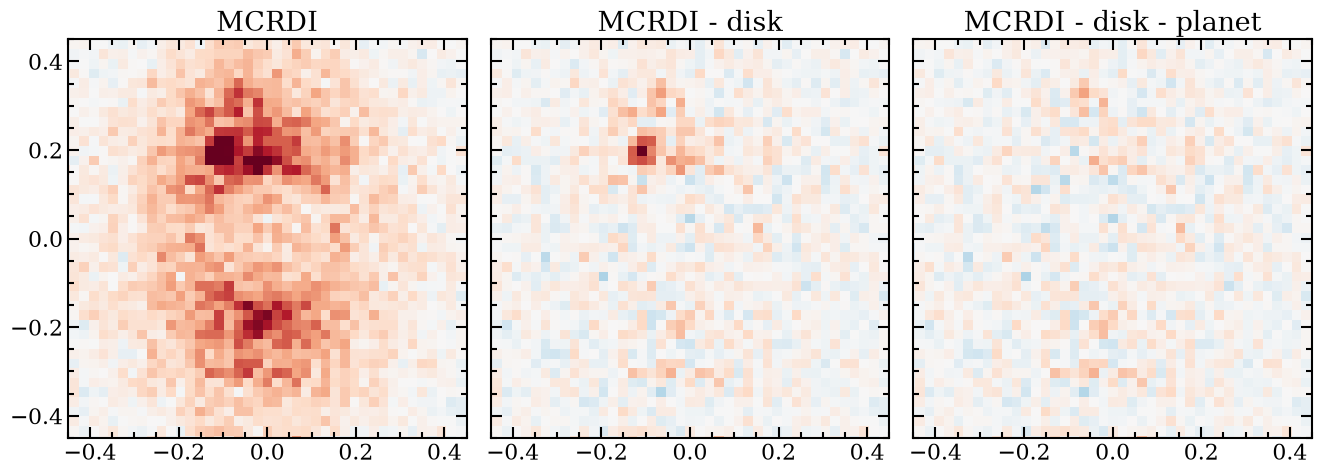

In [16]:
wdb.set_circumstellar_model(model_cube=coeffs[0]*model_cube + coeffs[1]*planet_cube(dxy_fit))
wdb.mcrdi_presets()
mcrdi_reduc = wdb.run_rdi(save_products=True)

wdb.set_circumstellar_model(model_cube=coeffs[0]*model_cube)
disk_reduc = wdb.make_model_reduc(match_reduc=mcrdi_reduc)
wdb.set_circumstellar_model(model_cube=coeffs[1]*planet_cube(dxy_fit))
planet_reduc = wdb.make_model_reduc(match_reduc=mcrdi_reduc)

fig,axes = quick_implot([mcrdi_reduc.im, (mcrdi_reduc - disk_reduc).im, (mcrdi_reduc - disk_reduc - planet_reduc).im],
                        cmap='RdBu_r', clim_perc=99.9, show=False, panelsize=(4.5,5.0), extent=mcrdi_reduc.extent,
                        lims=[-0.45,0.45], show_ticks=True)
for ax,label in zip(axes, ['MCRDI', 'MCRDI - disk', 'MCRDI - disk - planet']):
    ax.set_title(label)
plt.show()

Notes:
- MCRDI uses the disk + planet model, so the references are scaled without either; their models are then subtracted one by one.
- The planet flux is in unocculted detected e⁻/s, the same units as an unocculted star frame, so contrast is the ratio of the two. The model already includes the mask transmission at the planet position.
- Same caveat as part 2: the disk was injected with cgisim and fit with a corgisim grid. The disk residual left under the planet is part of the planet flux error.